In [1]:
%load_ext autoreload
%autoreload 2
from trader import StockDataLoader

period = "1y"
tickers = ["ASML", "NVDA", "SPY"]

env_data = StockDataLoader(tickers, period=period).load()

[*********************100%***********************]  3 of 3 completed


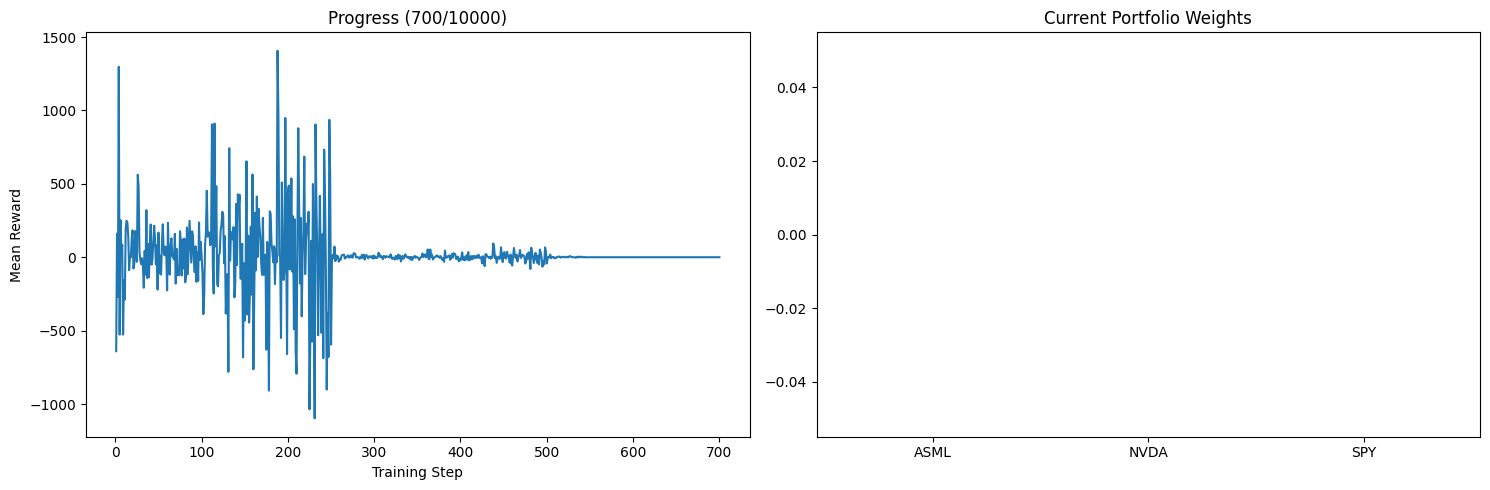

KeyboardInterrupt: 

In [4]:
%load_ext autoreload
%autoreload 2

import numpy as np
from stable_baselines3 import SAC

from trader import LivePlotCallback, TraderEnvironment

total_timesteps = 10000
budget = np.float32(10000.0)

env = TraderEnvironment(
    env_data=env_data,
    budget=budget,
)
callback = LivePlotCallback(
    total_timesteps=total_timesteps, trader_environment=env, tickers=tickers
)

model = SAC(
    "MlpPolicy",
    env,
    verbose=0,
    device="cuda",
)

trained_model = model.learn(
    total_timesteps=total_timesteps, log_interval=4, callback=callback
)